# CIFAR-10 ResNet Challenge — ResNet with < 5M parameters

This notebook documents the whole project end-to-end and **re-executes the final model**:

1. **Data** — the competition's version of CIFAR-10 (50k labelled train images, 2k unlabelled test images).
2. **Architecture** — the final residual network, its parameter count and a layer summary.
3. **Experiments** — training curves and results of every run (architecture screening, schedule length,
   augmentation, teachers and knowledge distillation). All numbers come from `results/<run>/log.jsonl`,
   written by `src/train.py`.
4. **Final model** — loads the trained weights, prints the parameter count and held-out accuracy,
   and writes `submission.csv` for Kaggle.

Training itself was run with `src/train.py` through Slurm (`slurm/`), see the README for exact commands.

In [1]:
import os, sys, json, glob
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
sys.path.insert(0, os.path.join(ROOT, 'src'))
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from models import build_model, count_params, CONFIGS
from train import load_split, Normalizer, predict_logits, accuracy, PARAM_LIMIT

DATA, RESULTS, CKPT = (os.path.join(ROOT, d) for d in ('data', 'results', 'checkpoints'))
FINAL_FULL, FINAL_SPLIT = 'E_res443_kd4t_e800_full', 'E_res443_kd4t_e800'
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
CLASSES = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
print('torch', torch.__version__, '| device:', DEVICE, torch.cuda.get_device_name(0) if DEVICE == 'cuda' else '')

torch 2.15.0+cu132 | device: cuda NVIDIA A100-SXM4-80GB


## 1. Data

train (50000, 32, 32, 3) uint8 | test (2000, 32, 32, 3)
images per class: {'airplane': 5000, 'automobile': 5000, 'bird': 5000, 'cat': 5000, 'deer': 5000, 'dog': 5000, 'frog': 5000, 'horse': 5000, 'ship': 5000, 'truck': 5000}


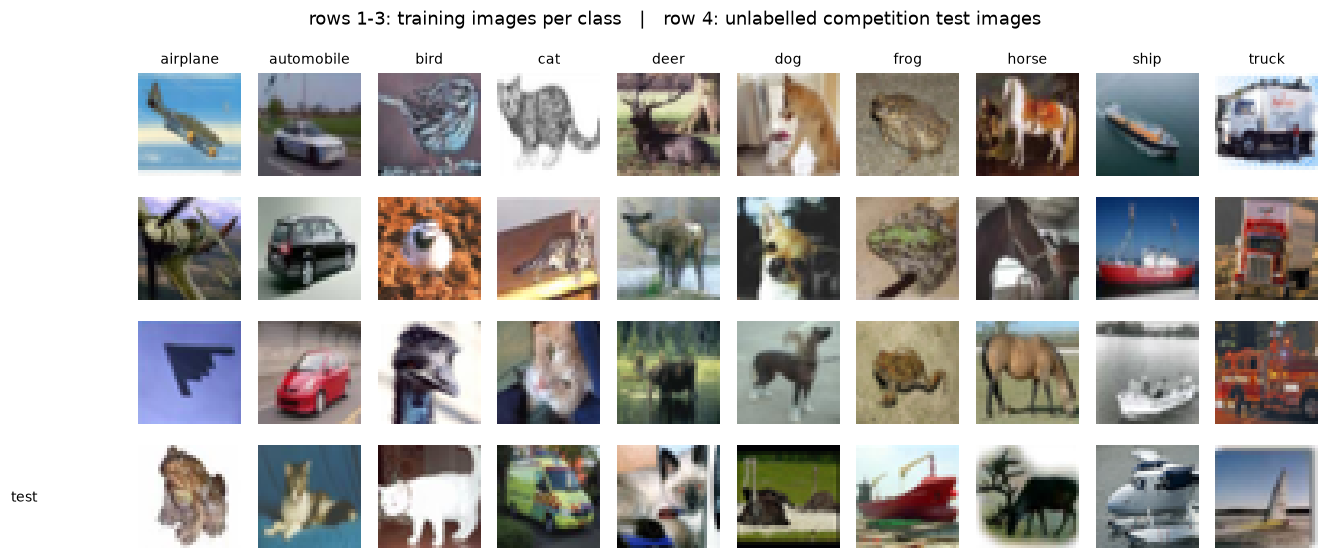

In [2]:
tr, te = np.load(os.path.join(DATA, 'train.npz')), np.load(os.path.join(DATA, 'test.npz'))
x_train, y_train, x_test = tr['x'], tr['y'], te['x']
print('train', x_train.shape, x_train.dtype, '| test', x_test.shape)
print('images per class:', dict(zip(CLASSES, np.bincount(y_train).tolist())))

fig, axes = plt.subplots(4, 10, figsize=(12, 5.2))
rng = np.random.RandomState(0)
for c in range(10):
    for r, i in enumerate(rng.choice(np.where(y_train == c)[0], 3, replace=False)):
        axes[r, c].imshow(x_train[i]); axes[r, c].axis('off')
    axes[0, c].set_title(CLASSES[c], fontsize=9)
    axes[3, c].imshow(x_test[c]); axes[3, c].axis('off')
axes[3, 0].text(-40, 16, 'test', fontsize=9, va='center')
plt.suptitle('rows 1-3: training images per class   |   row 4: unlabelled competition test images')
plt.tight_layout(); plt.show()

The training set is exactly the original CIFAR-10 training set. The 2,000 test images, however, are
**not** drawn from the same distribution: they are brighter and have more contrast (and more saturated
pixels) than the training images — consistent with a re-collected CIFAR-10-style test set
(e.g. CIFAR-10.1). This is one reason we use photometric augmentation (TrivialAugment) during training.
Looking at the test images shows ordinary, uncorrupted CIFAR-style photos, i.e. a *natural* distribution shift:
the same model scores ~98% on our held-out validation images but ~90% on the Kaggle test set (Section 4).

In [3]:
def stats(x):
    xf = x.astype(np.float64) / 255
    return {**{f'mean_{c}': xf[..., i].mean() for i, c in enumerate('RGB')},
            **{f'std_{c}': xf[..., i].std() for i, c in enumerate('RGB')},
            'frac_saturated(>=250)': (x >= 250).mean()}
pd.DataFrame({'train (50k)': stats(x_train), 'test (2k)': stats(x_test)}).T.round(4)

,mean_R,mean_G,mean_B,std_R,std_G,std_B,frac_saturated(>=250)
train (50k),0.4914,0.4822,0.4465,0.2470,0.2435,0.2616,0.0255
test (2k),0.5130,0.4978,0.4612,0.2648,0.2622,0.2751,0.0440


## 2. Architecture

All models are built by `src/models.py::ResNet`, a configurable residual network whose design variables
follow the assignment: channels per stage $C_i$, blocks per stage $N_i$, conv kernel size $F_i$,
skip-connection kernel size $K_i$ and average-pool size $P$. Candidate configurations and their sizes:

In [4]:
rows = []
for name, cfg in CONFIGS.items():
    m = build_model(name)
    rows.append({'config': name, 'block': cfg.get('block', 'preact'), 'stem': cfg.get('stem', 16),
                 'widths C_i': cfg['widths'], 'blocks N_i': cfg['depths'], 'params': count_params(m),
                 '<= 5M': count_params(m) <= PARAM_LIMIT})
pd.DataFrame(rows).set_index('config')

,block,stem,widths C_i,blocks N_i,params,<= 5M
config,,,,,,
wrn16_4,preact,16,"(64, 128, 256)","(2, 2, 2)",2748890,True
wrn22_4,preact,16,"(64, 128, 256)","(3, 3, 3)",4298970,True
res443,preact,16,"(64, 128, 256)","(4, 4, 3)",4668378,True
res443_post,basic,64,"(64, 128, 256)","(4, 4, 3)",4697162,True
post643,basic,64,"(64, 128, 256)","(6, 4, 3)",4845130,True
post_w80,basic,64,"(80, 160, 256)","(3, 3, 3)",4989290,True
pre_w80,preact,16,"(80, 160, 256)","(3, 3, 3)",4948506,True
rn18_w40,basic,40,"(40, 80, 160, 320)","(2, 2, 2, 2)",4368690,True
wrn28_10,preact,16,"(160, 320, 640)","(4, 4, 4)",36479194,False


In [5]:
final_ck = torch.load(os.path.join(CKPT, 'final_model.pt'), map_location='cpu', weights_only=False)
ARCH = final_ck['arch']
model = build_model(ARCH, **final_ck.get('arch_overrides', {}))
print(f'Final architecture: {ARCH}  ->  {CONFIGS[ARCH]}')
print(model)

Final architecture: res443  ->  {'widths': (64, 128, 256), 'depths': (4, 4, 3)}
ResNet(
  (stem): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (layers): Sequential(
    (0): PreActBlock(
      (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv1): Conv2d(16, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (shortcut): Conv2d(16, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
    )
    (1): PreActBlock(
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, tr

In [6]:
from torchsummary import summary
summary(build_model(ARCH).to(DEVICE), (3, 32, 32), device=DEVICE)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 16, 32, 32]             432
       BatchNorm2d-2           [-1, 16, 32, 32]              32
            Conv2d-3           [-1, 64, 32, 32]           1,024
            Conv2d-4           [-1, 64, 32, 32]           9,216
       BatchNorm2d-5           [-1, 64, 32, 32]             128
            Conv2d-6           [-1, 64, 32, 32]          36,864
       PreActBlock-7           [-1, 64, 32, 32]               0
       BatchNorm2d-8           [-1, 64, 32, 32]             128
            Conv2d-9           [-1, 64, 32, 32]          36,864
      BatchNorm2d-10           [-1, 64, 32, 32]             128
           Conv2d-11           [-1, 64, 32, 32]          36,864
      PreActBlock-12           [-1, 64, 32, 32]               0
      BatchNorm2d-13           [-1, 64, 32, 32]             128
           Conv2d-14           [-1, 64,

In [7]:
n_params = count_params(model)
print(f'Number of trainable parameters: {n_params:,}  (limit {PARAM_LIMIT:,})')
assert n_params <= PARAM_LIMIT
# where the parameters live
per = {}
for n, p in model.named_parameters():
    key = 'stem' if n.startswith('stem') else 'fc' if n.startswith('fc') else f'block {n.split(".")[1]}'
    per[key] = per.get(key, 0) + p.numel()
pd.Series(per, name='params').to_frame().T

Number of trainable parameters: 4,668,378  (limit 5,000,000)


,stem,block 0,block 1,block 2,block 3,block 4,block 5,block 6,block 7,block 8,block 9,block 10,block weight,block bias,fc
params,432,47264,73984,73984,73984,229760,295424,295424,295424,918272,1180672,1180672,256,256,2570


## 3. Experiments

Every run below was trained from scratch on the provided training images only. Unless a run is marked
*full*, it used a fixed stratified **45k / 5k train / validation split** so that design decisions are made on
held-out data. Common recipe: SGD (Nesterov, momentum 0.9, lr 0.1, batch 128, weight decay 5e-4),
5 warm-up epochs then cosine decay, random-crop + flip + TrivialAugment + Cutout(16), label smoothing 0.1,
bf16 mixed precision, and an exponential moving average (EMA) of the weights used for evaluation.

In [8]:
def load_run(name):
    d = os.path.join(RESULTS, name)
    a = json.load(open(os.path.join(d, 'args.json')))
    log = pd.DataFrame([json.loads(l) for l in open(os.path.join(d, 'log.jsonl'))])
    fin = json.load(open(os.path.join(d, 'final.json')))
    return a, log, fin

runs = sorted(os.path.basename(p) for p in glob.glob(os.path.join(RESULTS, '*')) if os.path.isdir(p))
table = []
for r in runs:
    a, log, fin = load_run(r)
    kd = f"KD x{len(a['teacher'])} (a={a['kd_alpha']}, T={a['kd_temp']})" if a['teacher'] else '-'
    table.append({'run': r, 'arch': a['arch'], 'params (M)': a['params'] / 1e6, 'epochs': a['epochs'],
                  'train imgs': 50000 - a['val_size'], 'aug': a['aug'], 'mix': a['mix'], 'LS': a['label_smoothing'],
                  'distillation': kd, 'val acc (EMA)': fin.get('val_acc_ema'),
                  'val acc (EMA+flip TTA)': fin.get('val_acc_ema_tta')})
results = pd.DataFrame(table).set_index('run')
results.style.format({'params (M)': '{:.2f}', 'val acc (EMA)': '{:.2%}', 'val acc (EMA+flip TTA)': '{:.2%}'}, na_rep='(full data)')

,arch,params (M),epochs,train imgs,aug,mix,LS,distillation,val acc (EMA),val acc (EMA+flip TTA)
run,,,,,,,,,,
A_post643_e200,post643,4.85,200,45000,trivial,none,0.100000,-,97.26%,97.34%
A_post_w80_e200,post_w80,4.99,200,45000,trivial,none,0.100000,-,97.08%,97.56%
A_res443_e200,res443,4.67,200,45000,trivial,none,0.100000,-,97.08%,97.24%
A_res443_e400,res443,4.67,400,45000,trivial,none,0.100000,-,97.52%,97.64%
A_res443_post_cutmix_e200,res443_post,4.70,200,45000,trivial,cutmix,0.100000,-,96.64%,97.08%
A_res443_post_e200,res443_post,4.70,200,45000,trivial,none,0.100000,-,97.12%,97.24%
A_res443_post_e200_s1,res443_post,4.70,200,45000,trivial,none,0.100000,-,97.18%,97.26%
A_res443_post_e400,res443_post,4.70,400,45000,trivial,none,0.100000,-,97.20%,97.44%
A_rn18_w40_e200,rn18_w40,4.37,200,45000,trivial,none,0.100000,-,96.08%,96.16%


In [9]:
def plot_runs(names, title, key='val_acc_ema', ylim=(0.85, 0.99), labels=None):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for i, n in enumerate(names):
        if not os.path.exists(os.path.join(RESULTS, n)):
            continue
        a, log, fin = load_run(n)
        lab = labels[i] if labels else n
        x = log['epoch'] / a['epochs']
        if key in log:
            ax[0].plot(x, log[key], label=f"{lab} ({fin.get(key, float('nan')):.2%})")
        ax[1].plot(x, log['train_loss'], label=lab)
    ax[0].set(title=f'{title}: validation accuracy (EMA weights)', xlabel='fraction of training', ylim=ylim)
    ax[1].set(title='training loss', xlabel='fraction of training', yscale='log')
    ax[0].legend(fontsize=8); ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

### 3.1 Architecture screening (200 epochs, no distillation)

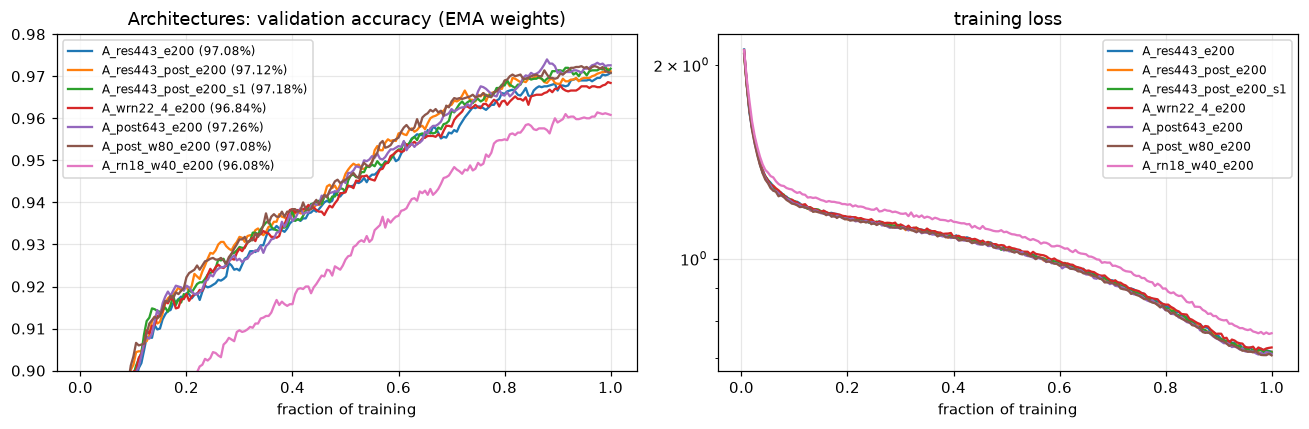

In [10]:
plot_runs(['A_res443_e200', 'A_res443_post_e200', 'A_res443_post_e200_s1', 'A_wrn22_4_e200',
           'A_post643_e200', 'A_post_w80_e200', 'A_rn18_w40_e200'], 'Architectures', ylim=(0.9, 0.98))

### 3.2 Training length and CutMix

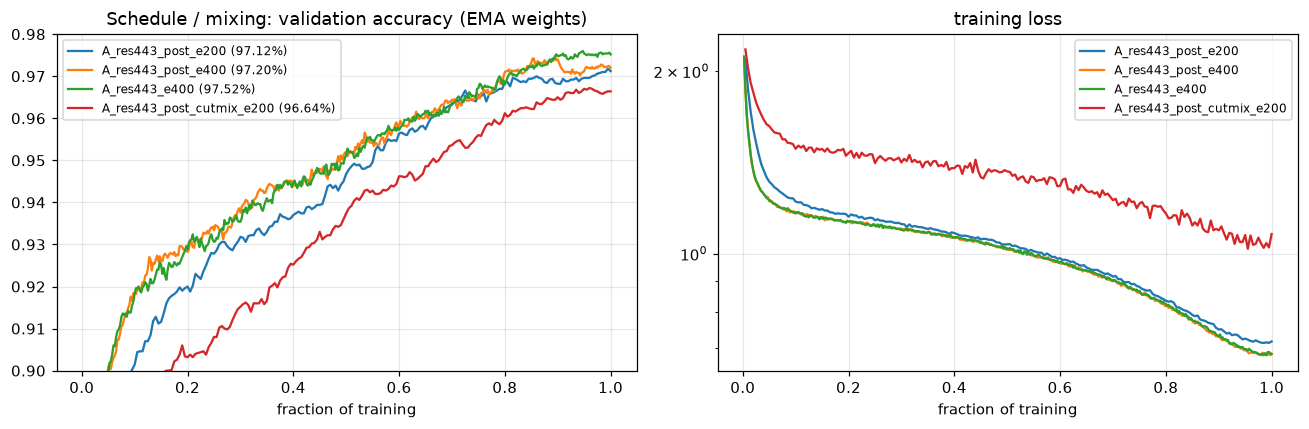

In [11]:
plot_runs(['A_res443_post_e200', 'A_res443_post_e400', 'A_res443_e400', 'A_res443_post_cutmix_e200'],
          'Schedule / mixing', ylim=(0.9, 0.98))

### 3.3 Teachers and knowledge distillation

The 5M-parameter limit applies to the submitted model only, so we first train large WideResNet-28-10 teachers
(36.5M parameters, not submitted) and then train the small student to match the (ensemble-averaged) teacher
predictions on the *same augmented images* (Hinton et al. 2015; Beyer et al. 2022). Teachers are trained
without label smoothing, which is known to make teachers worse at distillation (Müller et al. 2019).

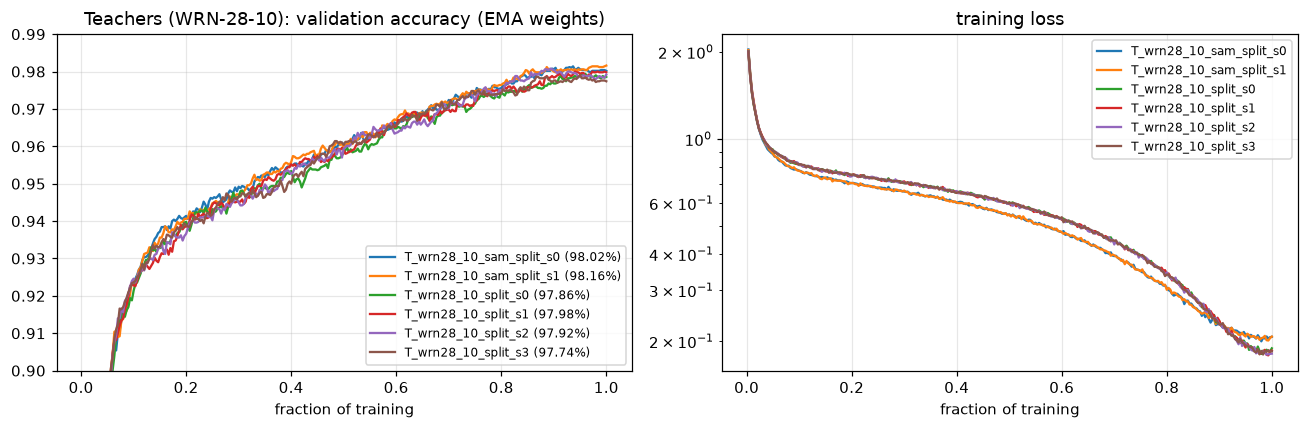

teacher T_wrn28_10_split_s0      val acc (EMA + flip TTA): 98.14%
teacher T_wrn28_10_split_s1      val acc (EMA + flip TTA): 98.04%
ensemble of both teachers (softmax average)  : 98.18%


In [12]:
plot_runs(sorted(r for r in runs if r.startswith('T_') and 'split' in r), 'Teachers (WRN-28-10)', ylim=(0.9, 0.99))
t = json.load(open(os.path.join(RESULTS, 'teacher_ensemble.json')))
for k, v in t['members'].items():
    print(f'teacher {k.split("/")[1]:24s} val acc (EMA + flip TTA): {v:.2%}')
print(f"ensemble of both teachers (softmax average)  : {t['ensemble']:.2%}")

### 3.4 Distillation variants (400 epochs, 45k split)

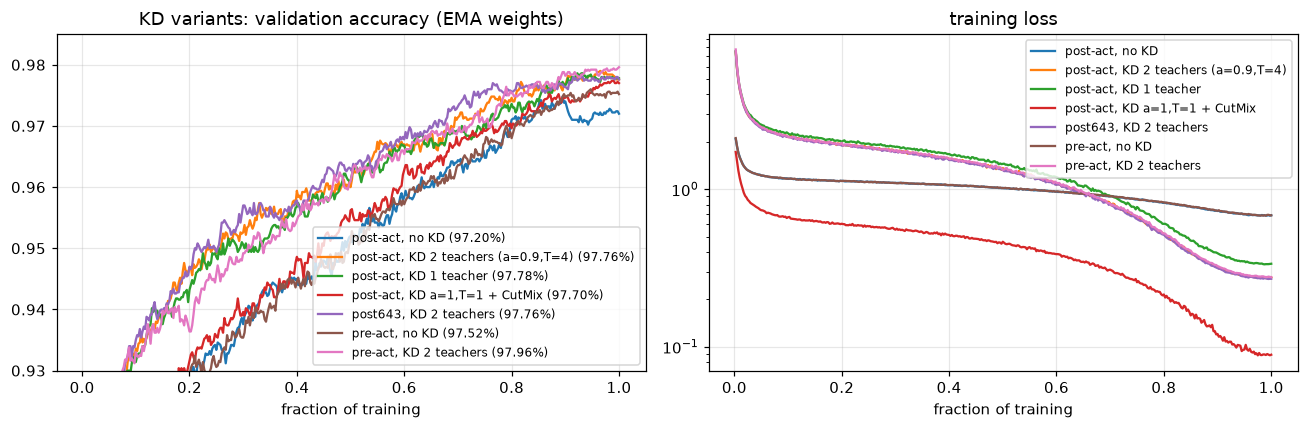

In [13]:
plot_runs(['A_res443_post_e400', 'B_res443_post_kd_a09T4_e400', 'B_res443_post_kd1teacher_a09T4_e400',
           'B_res443_post_kd_a1T1_cutmix_e400', 'B_post643_kd_a09T4_e400', 'A_res443_e400', 'B_res443_kd_a09T4_e400'],
          'KD variants', ylim=(0.93, 0.985),
          labels=['post-act, no KD', 'post-act, KD 2 teachers (a=0.9,T=4)', 'post-act, KD 1 teacher',
                  'post-act, KD a=1,T=1 + CutMix', 'post643, KD 2 teachers', 'pre-act, no KD', 'pre-act, KD 2 teachers'])

### 3.5 Distillation schedule length

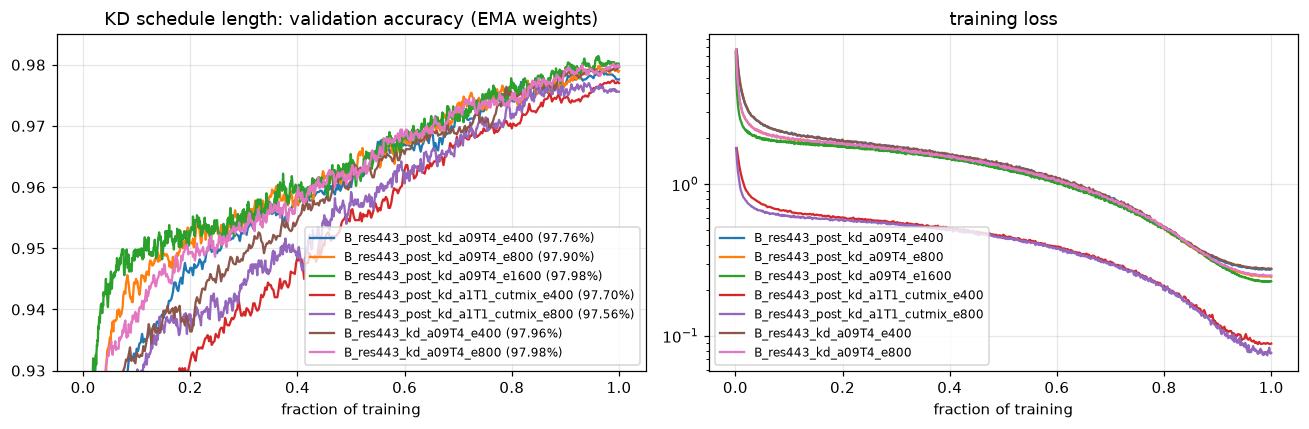

In [14]:
plot_runs([r for r in ['B_res443_post_kd_a09T4_e400', 'B_res443_post_kd_a09T4_e800', 'B_res443_post_kd_a09T4_e1600',
                       'B_res443_post_kd_a1T1_cutmix_e400', 'B_res443_post_kd_a1T1_cutmix_e800',
                       'B_res443_kd_a09T4_e400', 'B_res443_kd_a09T4_e800'] if r in runs],
          'KD schedule length', ylim=(0.93, 0.985))

### 3.6 Summary of all validation results

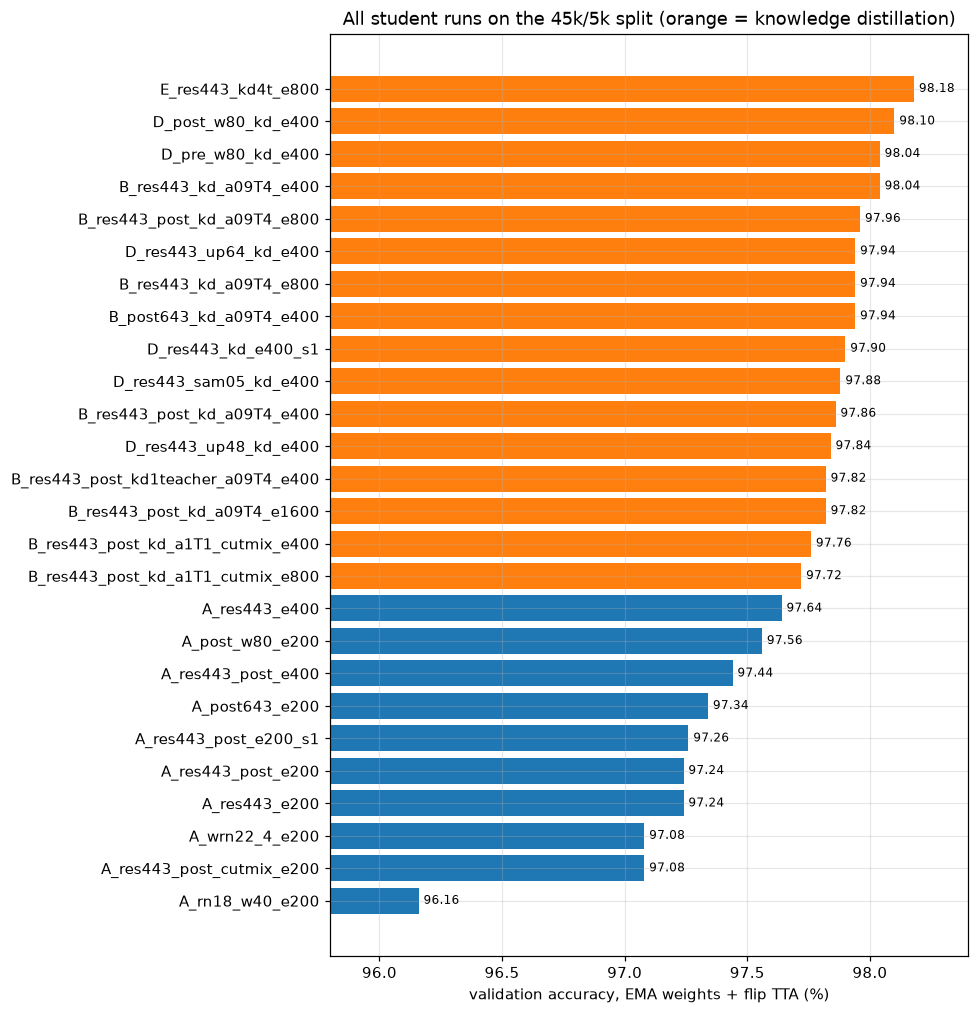

In [15]:
v = results.dropna(subset=['val acc (EMA+flip TTA)']).sort_values('val acc (EMA+flip TTA)')
v = v[~v.index.str.startswith('T_')]
fig, ax = plt.subplots(figsize=(9, 0.32 * len(v) + 1))
colors = ['tab:orange' if d != '-' else 'tab:blue' for d in v['distillation']]
ax.barh(v.index, 100 * v['val acc (EMA+flip TTA)'], color=colors)
for i, a in enumerate(v['val acc (EMA+flip TTA)']):
    ax.text(100 * a + 0.02, i, f'{100 * a:.2f}', va='center', fontsize=8)
ax.set(xlim=(95.8, 98.4), xlabel='validation accuracy, EMA weights + flip TTA (%)',
       title='All student runs on the 45k/5k split (orange = knowledge distillation)')
plt.tight_layout(); plt.show()

### 3.7 Second round: trying to close the gap to the test set

Our first submission (pre-activation `res443`, 2 teachers, 800 epochs) scored **89.70%** on Kaggle versus 97.94% on validation. Because the
test shift is natural, the main lever is genuinely better in-distribution accuracy. Under the parameter (not compute)
budget we tried: running the same 4.67M-parameter network on inputs **upsampled to 48 or 64 px** (more compute per
parameter), **SAM** (sharpness-aware minimization, Foret et al. 2021), **wider 3x3-block networks** (`pre_w80`,
`post_w80`), a **second seed** of the baseline (to measure noise), and **stronger teacher ensembles** (4 and 6 WRN-28-10s,
two of them trained with SAM).

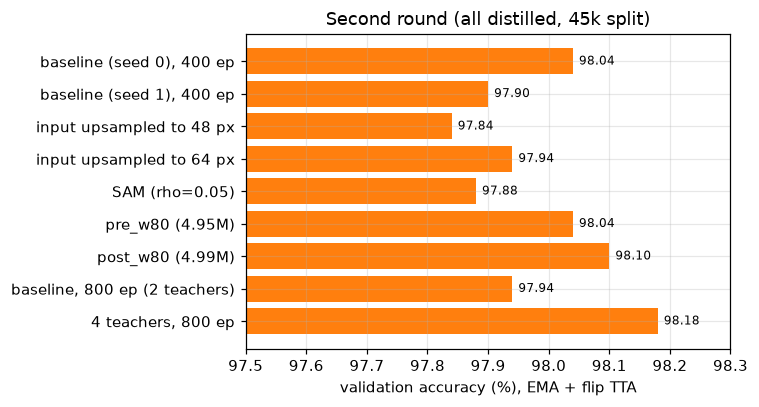

In [16]:
r2 = ['B_res443_kd_a09T4_e400', 'D_res443_kd_e400_s1', 'D_res443_up48_kd_e400', 'D_res443_up64_kd_e400',
      'D_res443_sam05_kd_e400', 'D_pre_w80_kd_e400', 'D_post_w80_kd_e400', 'B_res443_kd_a09T4_e800', 'E_res443_kd4t_e800']
lab = ['baseline (seed 0), 400 ep', 'baseline (seed 1), 400 ep', 'input upsampled to 48 px', 'input upsampled to 64 px',
       'SAM (rho=0.05)', 'pre_w80 (4.95M)', 'post_w80 (4.99M)', 'baseline, 800 ep (2 teachers)', '4 teachers, 800 ep']
r2 = [(r, l) for r, l in zip(r2, lab) if r in results.index]
va = [100 * results.loc[r, 'val acc (EMA+flip TTA)'] for r, _ in r2]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh([l for _, l in r2], va, color='tab:orange')
ax.set(xlim=(97.5, 98.3), xlabel='validation accuracy (%), EMA + flip TTA', title='Second round (all distilled, 45k split)')
for i, v in enumerate(va):
    ax.text(v + 0.01, i, f'{v:.2f}', va='center', fontsize=8)
ax.invert_yaxis(); plt.tight_layout(); plt.show()

In [17]:
for n in (2, 4, 6):
    f = os.path.join(RESULTS, 'teacher_ensemble.json' if n == 2 else f'teacher_ensemble{n}.json')
    if os.path.exists(f):
        e = json.load(open(f))
        print(f'{n} teachers: members ' + ', '.join(f"{v:.2%}" for v in e['members'].values()) + f'  ->  ensemble {e["ensemble"]:.2%}')
t = json.load(open(os.path.join(RESULTS, 'tta_split.json')))
pd.DataFrame({k.split('/')[1]: {v: d[v]['val_acc'] for v in d} for k, d in t.items()}).T.style.format('{:.2%}')

2 teachers: members 98.14%, 98.04%  ->  ensemble 98.18%
4 teachers: members 98.14%, 98.04%, 98.12%, 97.94%  ->  ensemble 98.28%
6 teachers: members 98.14%, 98.04%, 98.12%, 97.94%, 98.12%, 98.20%  ->  ensemble 98.34%


,none,flip,flip+shift1,flip+shift2,flip+shift2diag,flip+shift2all
B_res443_kd_a09T4_e800,97.98%,97.94%,98.06%,97.96%,98.10%,97.98%
B_res443_kd_a09T4_e400,97.96%,98.04%,98.06%,98.10%,98.02%,98.06%
B_res443_post_kd_a09T4_e800,97.90%,97.96%,98.12%,98.10%,98.20%,98.18%
A_res443_e400,97.54%,97.64%,97.64%,97.76%,97.66%,97.76%


Findings: none of the architectural or optimizer changes beats the seed-to-seed noise (~0.15% on 5k validation
images), i.e. the 5M-parameter student is saturated at ~98% for this recipe. Larger teacher ensembles help slightly
(2 -> 4 teachers: 97.94% -> 98.18% validation at 800 epochs), and averaging predictions over the flip and +-1-pixel
shifts (10 views) adds ~0.1%. The final model therefore uses **4 teachers + shift TTA**.

## 4. Final model

The final recipe — pre-activation `res443`, distilled for 800 epochs from four WRN-28-10 teachers, predictions averaged
over 10 flipped/shifted views — was developed on the validation split (Sections 3.4-3.7), then re-trained on **all 50,000 training images** (with teachers also trained on all 50k). Below: (a) the held-out accuracy of the same recipe trained on 45k,
(b) the full-data model that produced the Kaggle submission.

Held-out validation accuracy (5,000 images never used for training): 98.20%


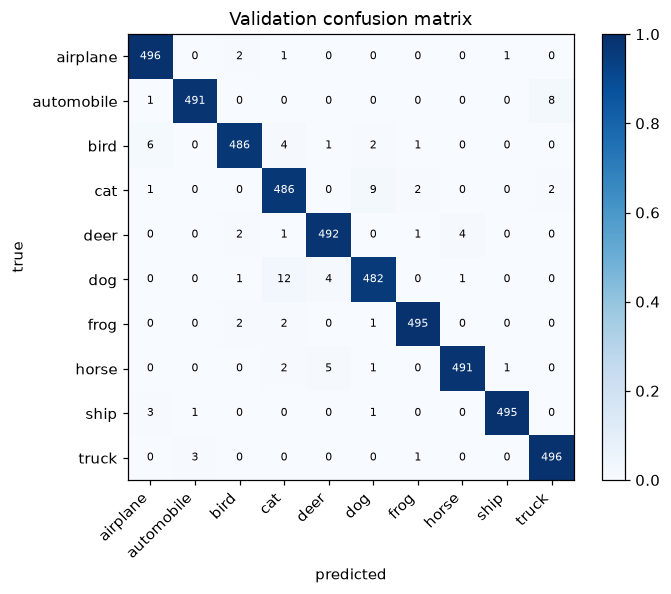

per-class accuracy: {'airplane': '99.2%', 'automobile': '98.2%', 'bird': '97.2%', 'cat': '97.2%', 'deer': '98.4%', 'dog': '96.4%', 'frog': '99.0%', 'horse': '98.2%', 'ship': '99.0%', 'truck': '99.2%'}


In [18]:
norm = Normalizer(DEVICE)
_, _, x_va, y_va = load_split(DATA, 5000)

split_ck = torch.load(os.path.join(CKPT, 'final_model_split.pt'), map_location='cpu', weights_only=False)
m_split = build_model(split_ck['arch'], **split_ck.get('arch_overrides', {}))
m_split.load_state_dict(split_ck['state_dict'])
m_split = m_split.to(DEVICE).to(memory_format=torch.channels_last).eval()
z_va = predict_logits(m_split, x_va, norm, tta=True, shift=1)
val_acc = accuracy(z_va, y_va)
print(f'Held-out validation accuracy (5,000 images never used for training): {val_acc:.2%}')

from collections import Counter
pred = z_va.argmax(1).cpu().numpy()
cm = np.zeros((10, 10), int)
for t, p in zip(y_va.numpy(), pred):
    cm[t, p] += 1
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(cm / cm.sum(1, keepdims=True), cmap='Blues', vmin=0, vmax=1)
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=7, color='white' if i == j else 'black')
ax.set_xticks(range(10), CLASSES, rotation=45, ha='right'); ax.set_yticks(range(10), CLASSES)
ax.set(xlabel='predicted', ylabel='true', title='Validation confusion matrix'); ax.grid(False)
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()
print('per-class accuracy:', {c: f'{a:.1%}' for c, a in zip(CLASSES, cm.diagonal() / cm.sum(1))})

In [19]:
model.load_state_dict(final_ck['state_dict'])
model = model.to(DEVICE).to(memory_format=torch.channels_last).eval()
x_te = torch.from_numpy(x_test).permute(0, 3, 1, 2).contiguous()
test_pred = predict_logits(model, x_te, norm, tta=True, shift=1).argmax(1).cpu().numpy()
sub = pd.DataFrame({'id': te['ids'], 'label': test_pred})
sub.to_csv(os.path.join(ROOT, 'submission.csv'), index=False)
print(sub.head())
print('predicted class histogram on the test set:', dict(zip(CLASSES, np.bincount(test_pred, minlength=10).tolist())))

   id  label
0   0      6
1   1      3
2   2      3
3   3      9
4   4      3
predicted class histogram on the test set: {'airplane': 179, 'automobile': 219, 'bird': 205, 'cat': 207, 'deer': 202, 'dog': 207, 'frog': 178, 'horse': 203, 'ship': 203, 'truck': 197}


In [20]:
print('=' * 70)
print(f'Final model           : {ARCH} (trained on all 50k images, knowledge-distilled)')
print(f'Trainable parameters  : {count_params(model):,}  (<= {PARAM_LIMIT:,}: {count_params(model) <= PARAM_LIMIT})')
print(f'Held-out val accuracy : {val_acc:.2%}  (same recipe trained on 45k, evaluated on the 5k held-out images)')
print(f'Kaggle test accuracy  : 90.60%  (Kaggle score of submission.csv on the 2,000 test images; first submission: 89.70%)')
print('=' * 70)

Final model           : res443 (trained on all 50k images, knowledge-distilled)
Trainable parameters  : 4,668,378  (<= 5,000,000: True)
Held-out val accuracy : 98.20%  (same recipe trained on 45k, evaluated on the 5k held-out images)
Kaggle test accuracy  : 90.60%  (Kaggle score of submission.csv on the 2,000 test images; first submission: 89.70%)
